In [1]:
import matplotlib.pyplot as plt
import numpy as np
# import cv2 as cv
import pandas as pd
import anndata as ad
import os,sys,re
import seaborn as sns

## Xenium IHC Data

In [8]:
import cv2
import tifffile
from ome_types import from_xml

spatial_dir = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial'
morphology_path = os.path.join(
    spatial_dir, 'GSM9509173_breast_breast_B1_B1_2_morphology_focus.ome.tif'
)
ihc_path = os.path.join(
    spatial_dir, 'ihc',
    'GSE311609_ihc_breast_breast_B4_B4_breast_breast_B1_B1_2.ome.tif',
)

# Level 4 retains enough nuclear/tissue detail for feature matching without
# loading either full-resolution slide. Level 3 is used for the final display.
REGISTRATION_LEVEL = 4
DISPLAY_LEVEL = 3
DAPI_CHANNEL = 0

In [9]:
def normalize_uint8(image, percentiles=(1, 99.8)):
    image = np.asarray(image, dtype=np.float32)
    lo, hi = np.percentile(image, percentiles)
    if hi <= lo:
        return np.zeros(image.shape, dtype=np.uint8)
    return (255 * np.clip((image - lo) / (hi - lo), 0, 1)).astype(np.uint8)


def level_to_full_matrix(full_yx, level_yx):
    # Homogeneous matrix mapping (x, y) at a pyramid level to level-0 pixels.
    return np.diag([full_yx[1] / level_yx[1], full_yx[0] / level_yx[0], 1.0])

In [10]:
with tifffile.TiffFile(morphology_path) as tif:
    morphology_full_shape = tif.series[0].shape[-2:]
    morphology_level_shapes = [level.shape[-2:] for level in tif.series[0].levels]
    morphology_dapi = tif.series[0].levels[REGISTRATION_LEVEL].asarray()

with tifffile.TiffFile(ihc_path) as tif:
    ihc_full_shape = tif.series[0].shape[-2:]
    ihc_level_shapes = [level.shape[-2:] for level in tif.series[0].levels]
    ihc_metadata = from_xml(tif.ome_metadata)
    ihc_dapi = tif.series[0].levels[REGISTRATION_LEVEL].asarray()[DAPI_CHANNEL]

print('morphology-focus levels:', morphology_level_shapes)
print('IHC levels:', ihc_level_shapes)
print('registration images:', morphology_dapi.shape, ihc_dapi.shape)

morphology-focus levels: [(27253, 36949), (13626, 18474), (6813, 9237), (3406, 4618), (1703, 2309), (851, 1154), (425, 577), (212, 288)]
IHC levels: [(50400, 34560), (25200, 17280), (12600, 8640), (6300, 4320), (3150, 2160), (1575, 1080), (787, 540), (393, 270)]
registration images: (1703, 2309) (3150, 2160)


In [5]:
# Detect scale/rotation/translation from DAPI morphology. SIFT is robust to the
# approximately 180-degree rotation and unequal OME pixel sizes in this pair.
fixed_u8 = normalize_uint8(morphology_dapi)
moving_u8 = normalize_uint8(ihc_dapi)
sift = cv2.SIFT_create(nfeatures=10_000, contrastThreshold=0.02)
fixed_keypoints, fixed_descriptors = sift.detectAndCompute(fixed_u8, None)
moving_keypoints, moving_descriptors = sift.detectAndCompute(moving_u8, None)

if fixed_descriptors is None or moving_descriptors is None:
    raise RuntimeError('SIFT did not find features in one of the DAPI images')

knn_matches = cv2.BFMatcher(cv2.NORM_L2).knnMatch(
    moving_descriptors, fixed_descriptors, k=2
)
good_matches = [m for m, n in knn_matches if m.distance < 0.70 * n.distance]
if len(good_matches) < 3:
    raise RuntimeError(f'Only {len(good_matches)} reliable feature matches found')

In [6]:
moving_points = np.float32(
    [moving_keypoints[m.queryIdx].pt for m in good_matches]
)
fixed_points = np.float32(
    [fixed_keypoints[m.trainIdx].pt for m in good_matches]
)

# This matrix maps IHC pixels to morphology-focus pixels at REGISTRATION_LEVEL.
ihc_to_morphology_registration, inlier_mask = cv2.estimateAffine2D(
    moving_points, fixed_points, method=cv2.RANSAC,
    ransacReprojThreshold=5.0, maxIters=10_000, confidence=0.999,
    refineIters=50,
)
if ihc_to_morphology_registration is None:
    raise RuntimeError('RANSAC could not estimate the IHC-to-morphology transform')

n_inliers = int(inlier_mask.sum())
if n_inliers < 10:
    raise RuntimeError(f'Registration is unreliable: only {n_inliers} RANSAC inliers')
print(f'{n_inliers}/{len(good_matches)} feature matches are RANSAC inliers')
print('IHC -> morphology affine (registration level):\n', ihc_to_morphology_registration)

100/120 feature matches are RANSAC inliers
IHC -> morphology affine (registration level):
 [[-2.33386196e+00 -6.57658658e-04  3.53066756e+03]
 [ 8.64932792e-04 -2.33254633e+00  6.07414059e+03]]


In [7]:
# Convert the fitted transform to level-0 coordinates. This is the transform to
# use for full-resolution coordinates or for exporting the registration.
reg_h = np.vstack([ihc_to_morphology_registration, [0, 0, 1]])
morphology_reg_to_full = level_to_full_matrix(
    morphology_full_shape, morphology_level_shapes[REGISTRATION_LEVEL]
)
ihc_reg_to_full = level_to_full_matrix(
    ihc_full_shape, ihc_level_shapes[REGISTRATION_LEVEL]
)
ihc_to_morphology_full = (
    morphology_reg_to_full @ reg_h @ np.linalg.inv(ihc_reg_to_full)
)
print('IHC level 0 -> morphology level 0:\n', ihc_to_morphology_full)

IHC level 0 -> morphology level 0:
 [[-2.33417782e+00 -6.57747666e-04  5.64983264e+04]
 [ 8.65091507e-04 -2.33297435e+00  9.72040830e+04]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [97]:
def transform_between_levels(full_transform, moving_full_yx, moving_level_yx,
                             fixed_full_yx, fixed_level_yx):
    moving_level_to_full = level_to_full_matrix(moving_full_yx, moving_level_yx)
    fixed_level_to_full = level_to_full_matrix(fixed_full_yx, fixed_level_yx)
    return np.linalg.inv(fixed_level_to_full) @ full_transform @ moving_level_to_full

ihc_to_morphology_display = transform_between_levels(
    ihc_to_morphology_full,
    ihc_full_shape, ihc_level_shapes[DISPLAY_LEVEL],
    morphology_full_shape, morphology_level_shapes[DISPLAY_LEVEL],
)


In [98]:
with tifffile.TiffFile(morphology_path) as tif:
    morphology_display = tif.series[0].levels[DISPLAY_LEVEL].asarray()
with tifffile.TiffFile(ihc_path) as tif:
    ihc_display = tif.series[0].levels[DISPLAY_LEVEL].asarray()

display_height, display_width = morphology_display.shape
registered_ihc = np.stack([
    cv2.warpAffine(
        channel, ihc_to_morphology_display[:2],
        (display_width, display_height), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT, borderValue=0,
    )
    for channel in ihc_display
])
registered_ihc_dapi = registered_ihc[DAPI_CHANNEL]

# Keep the pre-existing Xenium crop code below compatible.
img = morphology_display[None, ...]

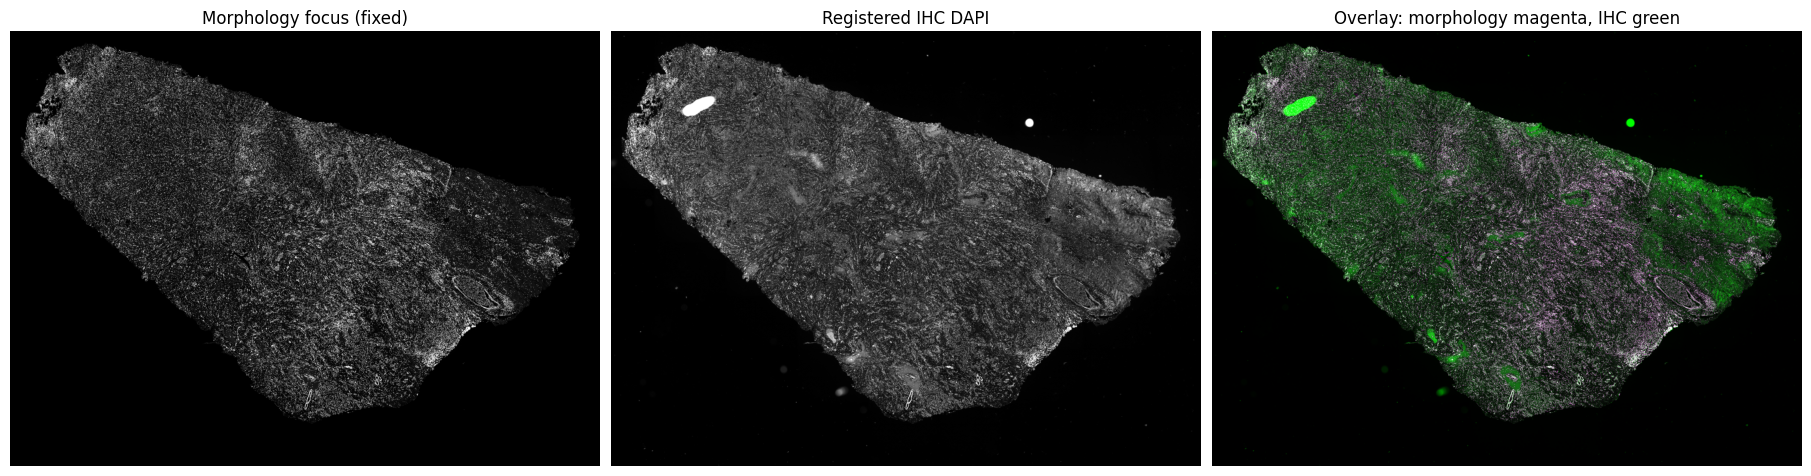

In [99]:
fixed_qc = normalize_uint8(morphology_display)
moving_qc = normalize_uint8(registered_ihc_dapi)
overlay = np.zeros((*fixed_qc.shape, 3), dtype=np.uint8)
overlay[..., 0] = fixed_qc       # morphology-focus DAPI in magenta
overlay[..., 2] = fixed_qc
overlay[..., 1] = moving_qc      # registered IHC DAPI in green

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(fixed_qc, cmap='gray')
axes[0].set_title('Morphology focus (fixed)')
axes[1].imshow(moving_qc, cmap='gray')
axes[1].set_title('Registered IHC DAPI')
axes[2].imshow(overlay)
axes[2].set_title('Overlay: morphology magenta, IHC green')
for ax in axes:
    ax.axis('off')

In [100]:
inliers = inlier_mask.ravel().astype(bool)
projected_points = cv2.transform(
    moving_points[inliers, None, :], ihc_to_morphology_registration
)[:, 0, :]
residuals = np.linalg.norm(projected_points - fixed_points[inliers], axis=1)
print(
    f'Median inlier residual at level {REGISTRATION_LEVEL}: '
    f'{np.median(residuals):.3f} px '
    f'(95th percentile {np.percentile(residuals, 95):.3f} px)'
)

Median inlier residual at level 4: 0.494 px (95th percentile 1.382 px)


In [101]:
[(channel.name, channel.color) for channel in ihc_metadata.images[0].pixels.channels]

[('DAPI (C1)', Color('#fff0', rgb=(255, 255, 255, 0.0))),
 ('Opal 570', Color('#ff00', rgb=(255, 255, 0, 0.0))),
 ('Opal 690', Color('#f000', rgb=(255, 0, 0, 0.0))),
 ('Sample AF', Color('#0000', rgb=(0, 0, 0, 0.0))),
 ('Opal 480', Color('#0ff0', rgb=(0, 255, 255, 0.0))),
 ('Opal 620', Color('#ff800000', rgb=(255, 128, 0, 0.0))),
 ('Opal 780 (C7)', Color('#f0f0', rgb=(255, 0, 255, 0.0))),
 ('Opal 520', Color('#0f00', rgb=(0, 255, 0, 0.0)))]

(8, 3406, 4618)


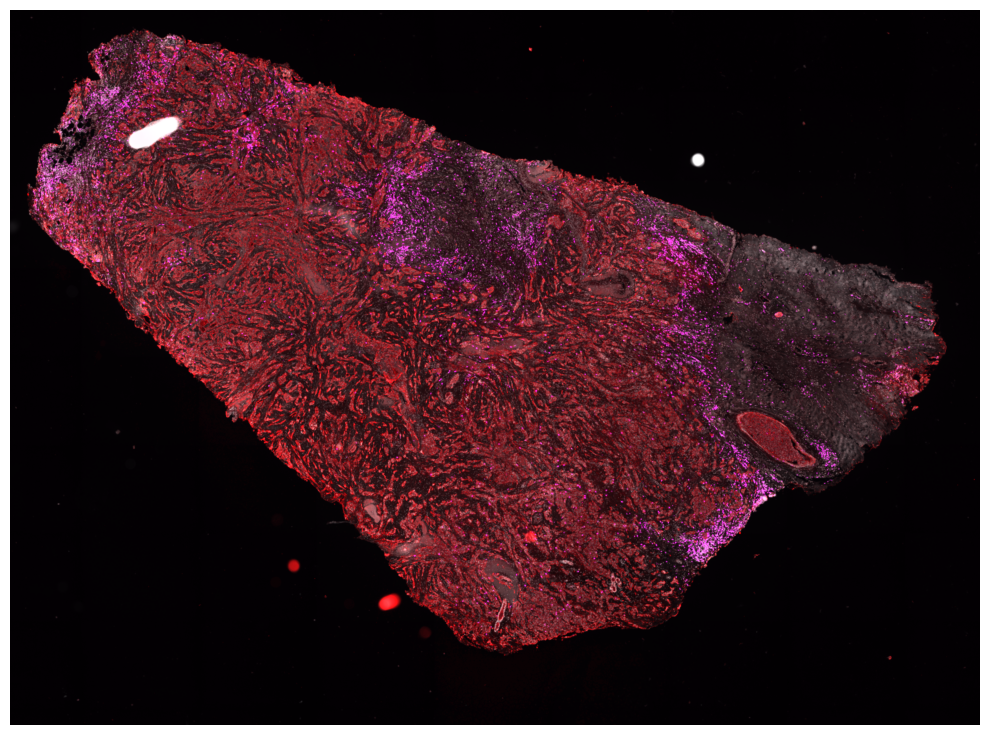

In [102]:
import numpy as np
import matplotlib.pyplot as plt
weights = np.array([
    1.0,  # DAPI
    0,  # Opal 570
    1,  # Opal 690
    0.0,  # AF
    0,  # Opal 480
    0,  # Opal 620
    1,  # Opal 780
    0,  # Opal 520
])
# RGB colors from the OME metadata
colors = np.array([
    [255, 255, 255],  # DAPI
    [255, 255,   0],  # Opal 570
    [255,   0,   0],  # Opal 690
    [  0,   0,   0],  # Sample AF
    [  0, 255, 255],  # Opal 480
    [255, 128,   0],  # Opal 620
    [255,   0, 255],  # Opal 780
    [  0, 255,   0],  # Opal 520
], dtype=float) / 255

rgb = np.zeros((*registered_ihc.shape[1:], 3), dtype=float)
print(registered_ihc.shape)
for c in range(registered_ihc.shape[0]):
    x = registered_ihc[c].astype(float)

    # Normalize each channel independently
    lo, hi = np.percentile(x, [0.01, 99.95])
    x = np.clip((x - lo) / max(hi - lo, 1), 0, 1)

    # Add this channel using its OME color
    rgb += weights[c]* x[..., None] * colors[c]

# Clip overlapping channels
rgb = np.clip(rgb, 0, 1)

plt.figure(figsize=(10, 10))
plt.imshow(rgb)
plt.axis("off")
plt.tight_layout()

In [103]:
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final/GSM9509173_breast_breast_B1_B1_2_rctd_annotated.h5ad')
# st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/GSM9509173_breast_breast_B1_B1_2.h5ad')

In [104]:
st_data = st_data[st_data.obs['harmony_cell_type'].str.contains('T')]

In [105]:
st_data

View of AnnData object with n_obs × n_vars = 12985 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split_X_primary_cell_type', 'split_X_w1_primary', 'split_X_first_type', 'split_X_purification_status', 'split_X_n_cell_types'
    var: 'feature_name', 'feature_type', 'genome', 'id', 'name', 'feature'
    uns: 'rctd_cell_type_names', 'rctd_class_df', 'rctd_postproces

In [106]:
tcell_coords = st_data.obs[['x_centroid','y_centroid']].values
tcell_coords

array([[ 904.12860107, 1695.93798828],
       [ 903.98425293, 1706.50708008],
       [ 890.81878662, 1685.95776367],
       ...,
       [5169.80615234, 1543.0567627 ],
       [5139.16699219, 1541.73156738],
       [5217.77636719, 1518.14562988]], shape=(12985, 2))

819 690
[7518.21630859 5058.03808594]


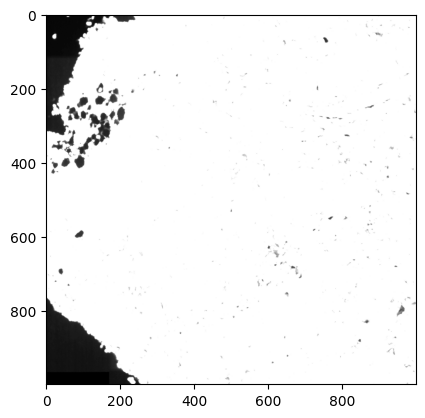

In [107]:
import matplotlib.pyplot as plt
import sys
sys.path.append('/home/jwinchel/Syndri/code')
import cv2 as cv
(x,y) = tcell_coords[500].astype(int)
print(x,y)

print(tcell_coords.max(axis=0))
crop_size=500
img_crop = img[0,x-crop_size:x+crop_size,y-crop_size:y+crop_size]

# img_crop = img
plt.imshow(img_crop,cmap='Grays_r',vmax=100)

### High-resolution registered IHC crops with Xenium transcripts

The H5AD centroids and transcript locations are in micrometers in the morphology-focus coordinate system. The functions below convert them to level-0 morphology pixels, use the inverse affine transform to read only the required level-0 IHC tiles, and warp each IHC crop back into the morphology frame.

In [148]:
xenium_h5ad_path = os.path.join(
    spatial_dir, '..', '..', 'results', 'final',
    'GSM9509173_breast_breast_B1_B1_2_rctd_annotated.h5ad',
)
xenium_transcripts_path = os.path.join(
    spatial_dir, 'GSM9509173_breast_breast_B1_B1_2_transcripts.parquet'
)

# x_centroid, y_centroid, x_location, and y_location are all in micrometers.
xenium_cells = ad.read_h5ad(xenium_h5ad_path, backed='r')
cell_centroids = xenium_cells.obs[[
    'cell_id', 'x_centroid', 'y_centroid', 'harmony_cell_type'
]].copy()
xenium_cells.file.close()
cell_centroids['cell_id'] = cell_centroids['cell_id'].astype(str)
cell_centroids = cell_centroids.set_index('cell_id', drop=False)

with tifffile.TiffFile(morphology_path) as tif:
    morphology_metadata = from_xml(tif.ome_metadata)
morphology_pixel_size_um = float(
    morphology_metadata.images[0].pixels.physical_size_x
)
morphology_to_ihc_full = np.linalg.inv(ihc_to_morphology_full)
print(f'Morphology-focus level-0 pixel size: {morphology_pixel_size_um} µm')

Morphology-focus level-0 pixel size: 0.2125 µm


In [149]:
def transform_xy(xy, matrix):
    xy = np.atleast_2d(np.asarray(xy, dtype=float))
    homogeneous = np.column_stack([xy, np.ones(len(xy))])
    transformed = homogeneous @ matrix.T
    return transformed[:, :2] / transformed[:, 2, None]


def read_ome_region(path, y_slice, x_slice, channel=None, level=0):
    """Decode only TIFF tiles intersecting a Y/X region (no zarr required)."""
    with tifffile.TiffFile(path) as tif:
        image_level = tif.series[0].levels[level]
        page = image_level.pages[0 if channel is None else channel]
        keyframe = page.keyframe
        if not keyframe.is_tiled:
            full = page.asarray()
            return full[y_slice, x_slice]

        height, width = page.shape[-2:]
        y0, y1, _ = y_slice.indices(height)
        x0, x1, _ = x_slice.indices(width)
        output = np.zeros((y1 - y0, x1 - x0), dtype=page.dtype)
        tiles_across = int(np.ceil(width / keyframe.tilewidth))
        tile_y0, tile_y1 = y0 // keyframe.tilelength, (y1 - 1) // keyframe.tilelength
        tile_x0, tile_x1 = x0 // keyframe.tilewidth, (x1 - 1) // keyframe.tilewidth

        for tile_y in range(tile_y0, tile_y1 + 1):
            for tile_x in range(tile_x0, tile_x1 + 1):
                tile_index = tile_y * tiles_across + tile_x
                tif.filehandle.seek(page.dataoffsets[tile_index])
                encoded = tif.filehandle.read(page.databytecounts[tile_index])
                tile, indices, _ = page.decode(encoded, tile_index)
                if tile is None:
                    continue
                tile = tile[0, :, :, 0]
                tile_origin_y, tile_origin_x = indices[2], indices[3]
                src_y0, src_x0 = max(y0, tile_origin_y), max(x0, tile_origin_x)
                src_y1 = min(y1, tile_origin_y + tile.shape[0])
                src_x1 = min(x1, tile_origin_x + tile.shape[1])
                output[src_y0-y0:src_y1-y0, src_x0-x0:src_x1-x0] = tile[
                    src_y0-tile_origin_y:src_y1-tile_origin_y,
                    src_x0-tile_origin_x:src_x1-tile_origin_x,
                ]
        return output


def compose_ihc_rgb(
    registered_channels, channel_colors=None, channel_gains=None,
    percentile_ranges=None,
):
    """Independently normalize, balance, and color registered IHC channels."""
    n_channels = len(registered_channels)
    if channel_colors is None:
        default_colors = np.array([
            [1, 1, 1],  # white
            [1, 0, 0],  # red
            [1, 0, 1],  # magenta
        ], dtype=float)
        if n_channels > len(default_colors):
            raise ValueError('Provide channel_colors when displaying more than 3 channels')
        channel_colors = default_colors[:n_channels]
    channel_colors = np.asarray(channel_colors, dtype=float)
    if channel_colors.shape != (n_channels, 3):
        raise ValueError(f'channel_colors must have shape ({n_channels}, 3)')
    if channel_gains is None:
        channel_gains = np.ones(n_channels)
    if percentile_ranges is None:
        percentile_ranges = [(1, 99.5)] * n_channels
    if len(channel_gains) != n_channels or len(percentile_ranges) != n_channels:
        raise ValueError('Provide one gain and percentile range per displayed channel')

    rgb = np.zeros((*registered_channels.shape[1:], 3), dtype=float)
    for image, color, gain, percentiles in zip(
        registered_channels, channel_colors, channel_gains, percentile_ranges
    ):
        image = image.astype(float)
        nonzero = image[image > 0]
        if nonzero.size:
            lo, hi = np.percentile(nonzero, percentiles)
            normalized = np.clip((image - lo) / max(hi - lo, 1), 0, 1)
        else:
            normalized = np.zeros_like(image)
        rgb += float(gain) * normalized[..., None] * color
    return np.clip(rgb, 0, 1)


def refine_registered_crop(
    registered_channels, morphology_crop, dapi_index=0,
    blur_sigma_px=3, max_shift_px=30,
):
    """Estimate and apply a guarded residual DAPI translation."""
    from skimage.registration import phase_cross_correlation
    from scipy.ndimage import gaussian_filter

    fixed = normalize_uint8(
        gaussian_filter(morphology_crop.astype(np.float32), sigma=blur_sigma_px)
    )
    moving = normalize_uint8(
        gaussian_filter(
            registered_channels[dapi_index].astype(np.float32), sigma=blur_sigma_px
        )
    )
    shift_yx, error, _ = phase_cross_correlation(
        fixed, moving, upsample_factor=10, normalization=None,
    )
    accepted = bool(
        np.all(np.isfinite(shift_yx))
        and np.linalg.norm(shift_yx) <= max_shift_px
    )
    if not accepted:
        return registered_channels, np.zeros(2), float(error), False

    dy, dx = shift_yx
    residual_transform = np.array([[1, 0, dx], [0, 1, dy]], dtype=np.float32)
    refined = np.stack([
        cv2.warpAffine(
            channel, residual_transform, (channel.shape[1], channel.shape[0]),
            flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0,
        )
        for channel in registered_channels
    ])
    return refined, shift_yx, float(error), True


def registered_ihc_cell_crop(
    cell_id, crop_size_um=80, ihc_channels=(0, 2, 6), qv_min=20, genes=None,
    channel_colors=None, channel_gains=None, percentile_ranges=None,
    point_size=8, local_refine=True,
    max_local_shift_um=6, ax=None,
):
    """Plot a level-0 IHC crop in the Xenium morphology frame with transcripts."""
    cell_id = str(cell_id)
    cell = cell_centroids.loc[cell_id]
    center_morph_xy = (
        cell[['x_centroid', 'y_centroid']].to_numpy(dtype=float)
        / morphology_pixel_size_um
    )
    half_size_px = int(round(crop_size_um / (2 * morphology_pixel_size_um)))
    x0_m = max(0, int(round(center_morph_xy[0])) - half_size_px)
    y0_m = max(0, int(round(center_morph_xy[1])) - half_size_px)
    x1_m = min(morphology_full_shape[1], x0_m + 2 * half_size_px)
    y1_m = min(morphology_full_shape[0], y0_m + 2 * half_size_px)
    out_width, out_height = x1_m - x0_m, y1_m - y0_m

    # Find the smallest source-IHC rectangle containing this morphology crop.
    morph_corners = np.array([
        [x0_m, y0_m], [x1_m, y0_m], [x1_m, y1_m], [x0_m, y1_m]
    ])
    ihc_corners = transform_xy(morph_corners, morphology_to_ihc_full)
    padding = 4
    x0_i = max(0, int(np.floor(ihc_corners[:, 0].min())) - padding)
    y0_i = max(0, int(np.floor(ihc_corners[:, 1].min())) - padding)
    x1_i = min(ihc_full_shape[1], int(np.ceil(ihc_corners[:, 0].max())) + padding)
    y1_i = min(ihc_full_shape[0], int(np.ceil(ihc_corners[:, 1].max())) + padding)
    if x1_i <= x0_i or y1_i <= y0_i:
        raise ValueError(f'Cell {cell_id} maps outside the registered IHC image')

    # Map source-ROI coordinates into the output morphology crop.
    source_local_to_global = np.array([[1, 0, x0_i], [0, 1, y0_i], [0, 0, 1]])
    morph_global_to_crop = np.array([[1, 0, -x0_m], [0, 1, -y0_m], [0, 0, 1]])
    local_affine = morph_global_to_crop @ ihc_to_morphology_full @ source_local_to_global

    registered_channels = []
    for channel in ihc_channels:
        source = read_ome_region(
            ihc_path, slice(y0_i, y1_i), slice(x0_i, x1_i), channel=channel
        )
        registered_channels.append(cv2.warpAffine(
            source, local_affine[:2], (out_width, out_height),
            flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0,
        ))
    registered_channels = np.stack(registered_channels)

    morphology_crop = read_ome_region(
        morphology_path, slice(y0_m, y1_m), slice(x0_m, x1_m)
    )
    local_shift_yx = np.zeros(2)
    local_error = np.nan
    refinement_accepted = False
    if local_refine:
        if DAPI_CHANNEL not in ihc_channels:
            raise ValueError('ihc_channels must include DAPI_CHANNEL for local refinement')
        dapi_stack_index = list(ihc_channels).index(DAPI_CHANNEL)
        registered_channels, local_shift_yx, local_error, refinement_accepted = (
            refine_registered_crop(
                registered_channels, morphology_crop, dapi_index=dapi_stack_index,
                blur_sigma_px=max(1, int(round(1 / morphology_pixel_size_um))),
                max_shift_px=max_local_shift_um / morphology_pixel_size_um,
            )
        )

    rgb = compose_ihc_rgb(
        registered_channels, channel_colors=channel_colors,
        channel_gains=channel_gains, percentile_ranges=percentile_ranges,
    )

    # Predicate pushdown returns only this cell's transcript rows.
    transcripts = pd.read_parquet(
        xenium_transcripts_path,
        filters=[('cell_id', '==', cell_id), ('qv', '>=', qv_min)],
        columns=['cell_id', 'feature_name', 'x_location', 'y_location', 'qv'],
    )
    if genes is not None:
        transcripts = transcripts[transcripts['feature_name'].isin(genes)]
    transcripts = transcripts.assign(
        crop_x=transcripts['x_location'] / morphology_pixel_size_um - x0_m,
        crop_y=transcripts['y_location'] / morphology_pixel_size_um - y0_m,
    )
    transcripts = transcripts[
        transcripts['crop_x'].between(0, out_width)
        & transcripts['crop_y'].between(0, out_height)
    ]

    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5), dpi=200)
    ax.imshow(rgb)
    if genes is None:
        ax.scatter(transcripts['crop_x'], transcripts['crop_y'], s=point_size,
                   c='cyan', edgecolors='none')
    else:
        sns.scatterplot(data=transcripts, x='crop_x', y='crop_y',
                        hue='feature_name', s=point_size, linewidth=0, ax=ax)
    shift_um = local_shift_yx[::-1] * morphology_pixel_size_um
    refinement_text = (
        f' | local Δ=({shift_um[0]:.1f}, {shift_um[1]:.1f}) µm'
        if refinement_accepted else (' | local refinement rejected' if local_refine else '')
    )
    ax.set_title(f"{cell_id} | {cell['harmony_cell_type']}{refinement_text}")
    ax.set_xlim(0, out_width)
    ax.set_ylim(out_height, 0)
    ax.axis('off')
    registration_qc = {
        'local_shift_yx_px': local_shift_yx,
        'local_shift_xy_um': shift_um,
        'phase_correlation_error': local_error,
        'local_refinement_accepted': refinement_accepted,
    }
    return ax, transcripts, registered_channels, registration_qc


In [150]:
from pathlib import Path

ANNOTATION_FILE = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/single-cell/41592_2026_3089_MOESM4_ESM.xlsx")
gene_annot = pd.read_excel(ANNOTATION_FILE, sheet_name="ST 4", skiprows=1)

cancer_genes = set(
    gene_annot.loc[gene_annot["Annotation_DB"].eq("malignant cell"), "Genes"].dropna()
)
tcell_genes = set(
    gene_annot.loc[
        gene_annot["Annotation_DB"].fillna("").str.contains("T", regex=False), "Genes"
    ].dropna()
)

# Give T-cell markers precedence if the annotation contains an overlap.
cancer_genes -= tcell_genes
print(f"Tumor markers: {len(cancer_genes):,}; T-cell markers: {len(tcell_genes):,}")

Tumor markers: 32; T-cell markers: 33


In [151]:
cell_centroids['harmony_cell_type'].str.contains('T', na=False)

cell_id
aaaabggd-1    False
aaaaelbn-1    False
aaacaiga-1    False
aaacalml-1    False
aaadbpdl-1    False
              ...  
oilohelo-1    False
oilonlha-1    False
oilppepb-1    False
oimamolj-1    False
oimbemlk-1    False
Name: harmony_cell_type, Length: 141262, dtype: bool

In [152]:
# Select genes present in this Xenium panel.
gene_mask = st_data.var["feature_name"].astype(str).isin(cancer_genes)
present_genes = st_data.var.loc[gene_mask, "feature_name"].astype(str).tolist()

print(f"{len(present_genes)} cancer genes found:")
print(present_genes)

# Select T-cell annotations.
cell_types = st_data.obs["harmony_cell_type"].astype(str)
tcell_mask = cell_types.str.contains(
    r"\bT(?:[- ]|$)",
    case=False,
    regex=True,
    na=False,
)

tcell_data = st_data[tcell_mask, gene_mask]

# Sum cancer-gene transcript counts per cell.
cancer_counts = tcell_data.X.sum(axis=1)
cancer_counts = np.asarray(cancer_counts).ravel()

ranked_tcells = tcell_data.obs[
    ["cell_id", "x_centroid", "y_centroid", "harmony_cell_type"]
].copy()

ranked_tcells["cancer_transcript_count"] = cancer_counts
ranked_tcells = ranked_tcells.sort_values(
    "cancer_transcript_count",
    ascending=False,
)

example_cell_ids = ranked_tcells.head(3)['cell_id'].values

32 cancer genes found:
['ABCC11', 'APOBEC3B', 'AR', 'CAV1', 'CCND1', 'CDH1', 'CEACAM6', 'CENPF', 'CXCL12', 'EGFR', 'ERBB2', 'ESR1', 'FOXA1', 'GATA3', 'KIT', 'KRT7', 'LDHB', 'LRRC15', 'MDM2', 'PCLAF', 'PGR', 'PTGDS', 'RUNX1', 'S100A4', 'SCD', 'SFRP1', 'SNAI1', 'TACSTD2', 'TCF4', 'TOP2A', 'ZEB1', 'ZEB2']


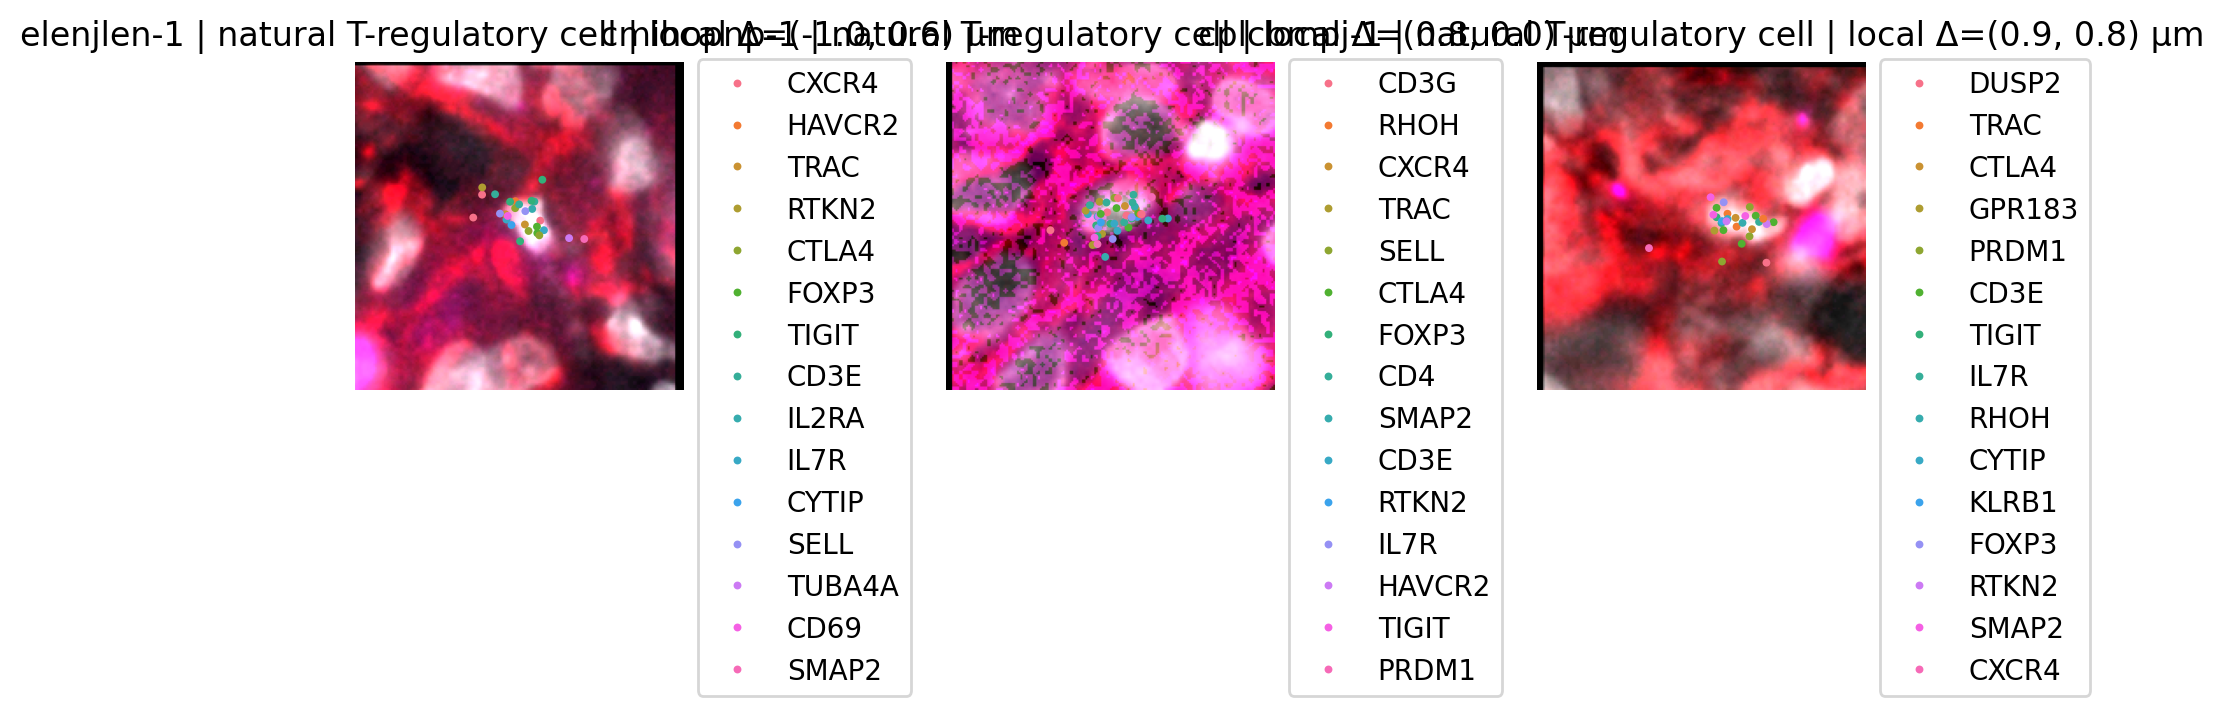

In [153]:
# Example: three T-cell crops selected using centroids from the annotated H5AD.
# example_cell_ids = cell_centroids.loc[
#     cell_centroids['harmony_cell_type'].str.contains('T', na=False), 'cell_id'
# ].iloc[200:203].tolist()


fig, axes = plt.subplots(1, len(example_cell_ids), figsize=(9, 3), dpi=200)
for cell_id, ax in zip(example_cell_ids, np.atleast_1d(axes)):
    registered_ihc_cell_crop(
        cell_id, crop_size_um=40, qv_min=20,
        genes=tcell_genes, ax=ax,
    )
    ax.legend(bbox_to_anchor=(1,1.05))
fig.tight_layout()

### Before and after Syndri transcript cleaning

This uses the count-weighted, cell-type-specific target-removed-fraction thresholding from `context_analysis/VariancePreservation.ipynb` and `eval/metrics_eval.py`. A cell-gene entry is removed when `syndri_admix_probs_X >= threshold` for that cell's `harmony_cell_type`.

In [154]:
import scipy.sparse as sp

SYNDRI_TARGET_REMOVED_FRACTION = 0.5
SYNDRI_CELL_TYPE_SPECIFIC = True


def to_csr(X):
    if sp.issparse(X):
        return X.tocsr().astype(np.float32)
    return sp.csr_matrix(np.asarray(X, dtype=np.float32))


def expressed_counts_and_probabilities(X, probabilities):
    X = to_csr(X)
    rows, cols = X.nonzero()
    counts = X.data.astype(float)
    pvals = np.asarray(probabilities[rows, cols]).ravel().astype(float)
    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    return counts[good], pvals[good]


def threshold_for_removed_fraction(probabilities, X, target_removed_fraction):
    # Count-weighted threshold selection, identical to the metrics notebooks.
    target_removed_fraction = float(target_removed_fraction)
    if not 0 <= target_removed_fraction <= 1:
        raise ValueError('target_removed_fraction must be between 0 and 1')
    if target_removed_fraction == 0:
        return np.inf, 0.0
    if target_removed_fraction == 1:
        return -np.inf, 1.0
    counts, pvals = expressed_counts_and_probabilities(X, probabilities)
    if counts.size == 0:
        raise ValueError('No expressed transcripts found (X > 0)')
    order = np.argsort(pvals)[::-1]
    p_sorted, c_sorted = pvals[order], counts[order]
    index = min(
        int(np.searchsorted(
            np.cumsum(c_sorted), target_removed_fraction * counts.sum(), side='left'
        )),
        len(p_sorted) - 1,
    )
    threshold = float(p_sorted[index])
    achieved = float(c_sorted[p_sorted >= threshold].sum() / counts.sum())
    return threshold, achieved


# Load once because thresholds are selected from the complete slice, not plotted cells.
syndri_data = ad.read_h5ad(xenium_h5ad_path)
syndri_counts = to_csr(syndri_data.X)
syndri_probabilities = syndri_data.layers['syndri_admix_probs_X']
syndri_probabilities = (
    syndri_probabilities.toarray()
    if sp.issparse(syndri_probabilities)
    else np.asarray(syndri_probabilities)
)
syndri_cell_types = syndri_data.obs['harmony_cell_type'].astype(str).to_numpy()
syndri_gene_names = syndri_data.var['feature_name'].astype(str).to_numpy()
syndri_gene_to_col = {gene: i for i, gene in enumerate(syndri_gene_names)}
syndri_cell_id_to_row = {
    str(cell_id): i for i, cell_id in enumerate(syndri_data.obs['cell_id'].astype(str))
}

syndri_cell_type_thresholds = {}
syndri_cell_type_achieved = {}
if SYNDRI_CELL_TYPE_SPECIFIC:
    for cell_type in pd.unique(syndri_cell_types):
        mask = syndri_cell_types == cell_type
        threshold, achieved = threshold_for_removed_fraction(
            syndri_probabilities[mask], syndri_counts[mask],
            SYNDRI_TARGET_REMOVED_FRACTION,
        )
        syndri_cell_type_thresholds[cell_type] = threshold
        syndri_cell_type_achieved[cell_type] = achieved
else:
    threshold, achieved = threshold_for_removed_fraction(
        syndri_probabilities, syndri_counts, SYNDRI_TARGET_REMOVED_FRACTION
    )
    syndri_cell_type_thresholds = dict.fromkeys(pd.unique(syndri_cell_types), threshold)
    syndri_cell_type_achieved = dict.fromkeys(pd.unique(syndri_cell_types), achieved)

pd.DataFrame({
    'cell_type': syndri_cell_type_thresholds.keys(),
    'admix_prob_threshold': syndri_cell_type_thresholds.values(),
    'achieved_removed_fraction': syndri_cell_type_achieved.values(),
}).sort_values('cell_type').reset_index(drop=True)

,cell_type,admix_prob_threshold,achieved_removed_fraction
0,"CD4-positive, alpha-beta memory T cell",0.974916,0.500003
1,capillary endothelial cell,0.922851,0.500001
2,classical monocyte,0.987285,0.500003
3,cytotoxic T cell,0.979880,0.500001
4,fibroblast of breast,0.977103,0.500012
5,fibroblast of lung,0.549477,0.500000
6,macrophage,0.939250,0.500000
7,malignant cell,0.331980,0.500001
8,mast cell,0.992467,0.500002
9,natural T-regulatory cell,0.988238,0.500006


In [155]:
def annotate_transcripts_with_syndri(transcripts, cell_id):
    """Attach the cell-gene probability and selected removal decision."""
    cell_id = str(cell_id)
    row = syndri_cell_id_to_row[cell_id]
    cell_type = syndri_cell_types[row]
    threshold = syndri_cell_type_thresholds[cell_type]
    gene_columns = transcripts['feature_name'].map(syndri_gene_to_col)
    probabilities = np.full(len(transcripts), np.nan)
    valid = gene_columns.notna().to_numpy()
    probabilities[valid] = syndri_probabilities[
        row, gene_columns[valid].astype(int).to_numpy()
    ]
    annotated = transcripts.copy()
    annotated['syndri_admix_prob'] = probabilities
    annotated['admix_prob_threshold'] = threshold
    annotated['is_removed'] = annotated['syndri_admix_prob'] >= threshold
    return annotated


def syndri_cell_metrics(cell_id):
    """Calculate count-weighted whole-cell metrics using the H5AD matrices."""
    cell_id = str(cell_id)
    row = syndri_cell_id_to_row[cell_id]
    cell_type = syndri_cell_types[row]
    threshold = syndri_cell_type_thresholds[cell_type]
    counts = syndri_counts.getrow(row).toarray().ravel()
    probabilities = np.asarray(syndri_probabilities[row]).ravel()
    removed_mask = (counts > 0) & np.isfinite(probabilities) & (probabilities >= threshold)
    raw_count = float(counts.sum())
    removed_count = float(counts[removed_mask].sum())
    removed_genes = syndri_gene_names[removed_mask].tolist()
    return {
        'cell_id': cell_id,
        'cell_type': cell_type,
        'admix_prob_threshold': float(threshold),
        'raw_transcript_count': raw_count,
        'removed_transcript_count': removed_count,
        'retained_transcript_count': raw_count - removed_count,
        'cell_removed_fraction': removed_count / raw_count if raw_count else np.nan,
        'removed_gene_count': int(removed_mask.sum()),
        'removed_genes': removed_genes,
        'cell_type_achieved_removed_fraction': syndri_cell_type_achieved[cell_type],
    }


def plot_syndri_before_after_crop(
    cell_id, crop_size_um=80, qv_min=20, genes=None,
    ihc_channels=(0, 2, 6), channel_colors=None, channel_gains=None,
    percentile_ranges=None, max_local_shift_um=6, point_size=9,
):
    # Generate and refine the registered crop only once.
    scratch_fig, scratch_ax = plt.subplots()
    _, transcripts, registered_channels, registration_qc = registered_ihc_cell_crop(
        cell_id, crop_size_um=crop_size_um, ihc_channels=ihc_channels,
        qv_min=qv_min, genes=genes, channel_colors=channel_colors,
        channel_gains=channel_gains, percentile_ranges=percentile_ranges,
        local_refine=True,
        max_local_shift_um=max_local_shift_um, ax=scratch_ax,
    )
    plt.close(scratch_fig)
    transcripts = annotate_transcripts_with_syndri(transcripts, cell_id)
    metrics = syndri_cell_metrics(cell_id)

    # Preserve the previous full-range rendering unless custom percentiles are supplied.
    balance_percentiles = (
        [(0, 100)] * len(registered_channels)
        if percentile_ranges is None else percentile_ranges
    )
    rgb = compose_ihc_rgb(
        registered_channels, channel_colors=channel_colors,
        channel_gains=channel_gains, percentile_ranges=balance_percentiles,
    )

    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), dpi=200, sharex=True, sharey=True)
    for ax, title in zip(axes, ['Before cleaning', 'After Syndri cleaning']):
        ax.imshow(rgb)
        ax.set_title(title)
        ax.axis('off')

    kept = transcripts[~transcripts['is_removed']]
    removed = transcripts[transcripts['is_removed']]
    axes[0].scatter(kept['crop_x'], kept['crop_y'], s=point_size, c='#22D3EE',
                    edgecolors='none', label='Retained')
    axes[0].scatter(removed['crop_x'], removed['crop_y'], s=point_size * 1.5,
                    c='#FACC15', marker='x', linewidths=0.8, label='Predicted removed')
    axes[1].scatter(kept['crop_x'], kept['crop_y'], s=point_size, c='#22D3EE',
                    edgecolors='none', label='Retained')

    fig.suptitle(
        f"{cell_id} | {metrics['cell_type']} | "
        f"p ≥ {metrics['admix_prob_threshold']:.3f} | "
        f"removed {metrics['removed_transcript_count']:.0f}/"
        f"{metrics['raw_transcript_count']:.0f} "
        f"({metrics['cell_removed_fraction']:.1%})",
        fontsize=9,
    )
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0.08, 1, 0.92))
    return fig, axes, transcripts, metrics, registration_qc


cell_id                                                                       cmihopnp-1
cell_type                                                      natural T-regulatory cell
admix_prob_threshold                                                            0.988238
raw_transcript_count                                                               272.0
removed_transcript_count                                                           161.0
retained_transcript_count                                                          111.0
cell_removed_fraction                                                           0.591912
removed_gene_count                                                                    23
removed_genes                          [ABCC11, ADAM9, ALDH1A3, CD9, DSC2, EGFR, ENAH...
cell_type_achieved_removed_fraction                                             0.500006
dtype: object

,feature_name,syndri_admix_prob,admix_prob_threshold,x_location,y_location
28,KRT7,0.999715,0.988238,1247.279419,1864.514038
29,KRT7,0.999715,0.988238,1247.231689,1860.880615
15,KRT7,0.999715,0.988238,1248.476074,1858.371338
16,KRT7,0.999715,0.988238,1249.508057,1861.276001
143,KRT7,0.999715,0.988238,1255.557007,1859.853760
...,...,...,...,...,...
226,EGFR,0.996432,0.988238,1258.435791,1860.427124
56,RUNX1,0.990487,0.988238,1252.417969,1864.314819
181,RUNX1,0.990487,0.988238,1254.179199,1862.094727
268,RUNX1,0.990487,0.988238,1256.715576,1863.885010


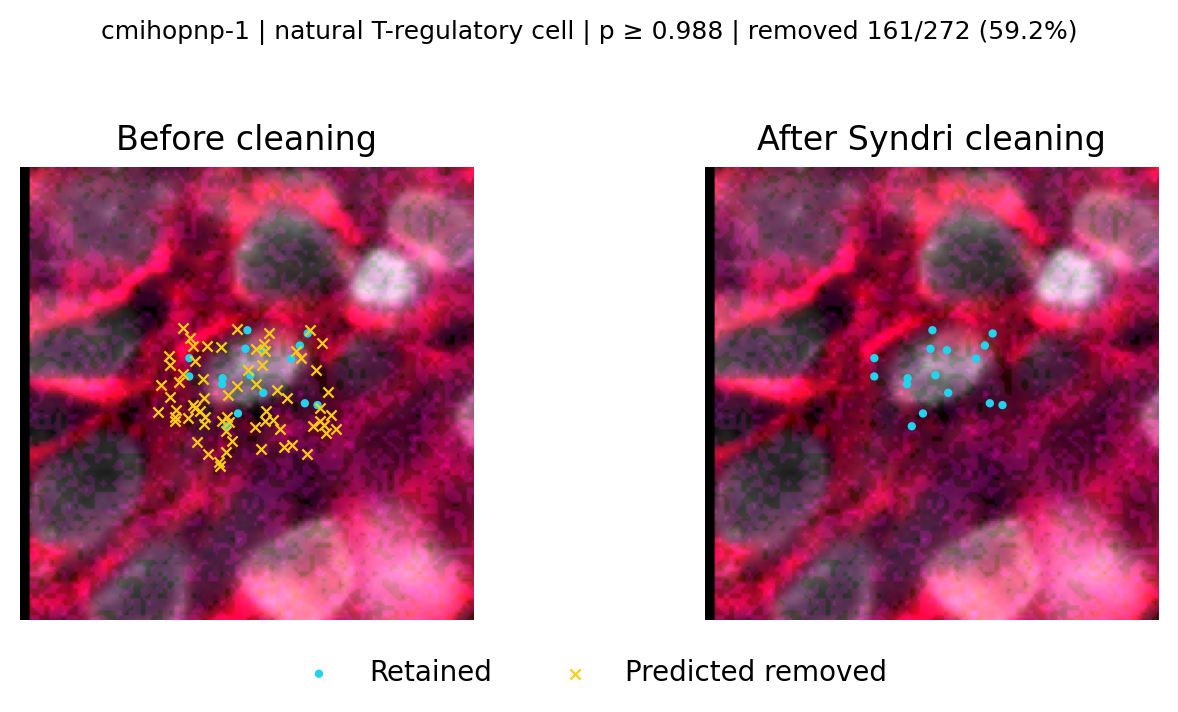

In [163]:
# Replace this with any cell_id from cell_centroids.
example_cell_id = example_cell_ids[1]
fig, axes, plotted_transcripts, removal_metrics, registration_qc = (
    plot_syndri_before_after_crop(
        example_cell_id, crop_size_um=40, qv_min=20,
        genes=cancer_genes,  # Or provide a gene list to restrict the displayed transcripts.
        channel_gains=[0.8, 1.0, 0.4],
        percentile_ranges=[
            (2, 99.8),   # DAPI/white
            (2, 99.8),   # red
            (2, 99.8),  # magenta: suppress background and saturation
        ]
    )
)
display(pd.Series(removal_metrics))
display(
    plotted_transcripts.loc[plotted_transcripts['is_removed'], [
        'feature_name', 'syndri_admix_prob', 'admix_prob_threshold',
        'x_location', 'y_location',
    ]].sort_values('syndri_admix_prob', ascending=False)
)

In [168]:
plotted_transcripts[plotted_transcripts['syndri_admix_prob']<plotted_transcripts['admix_prob_threshold']].sort_values(by=['syndri_admix_prob'])

,cell_id,feature_name,x_location,y_location,qv,crop_x,crop_y,syndri_admix_prob,admix_prob_threshold,is_removed
68,cmihopnp-1,S100A4,1252.319580,1867.063721,40.000000,85.268555,107.181641,0.303725,0.988238,False
69,cmihopnp-1,S100A4,1253.306030,1865.934570,30.157600,89.910645,101.868164,0.303725,0.988238,False
70,cmihopnp-1,S100A4,1255.529419,1864.115601,29.551842,100.373535,93.308594,0.303725,0.988238,False
132,cmihopnp-1,S100A4,1251.955566,1862.827515,31.746132,83.555664,87.247070,0.303725,0.988238,False
179,cmihopnp-1,AR,1254.139282,1858.598389,40.000000,93.831543,67.344727,0.605188,0.988238,False
74,cmihopnp-1,LDHB,1251.905151,1863.358154,32.961613,83.318359,89.744141,0.686733,0.988238,False
127,cmihopnp-1,CDH1,1258.762817,1859.947510,40.000000,115.589355,73.694336,0.906798,0.988238,False
71,cmihopnp-1,APOBEC3B,1257.987183,1861.108765,29.888178,111.939453,79.158203,0.958864,0.988238,False
263,cmihopnp-1,SFRP1,1259.199951,1865.036499,40.000000,117.646484,97.642578,0.959717,0.988238,False
270,cmihopnp-1,CCND1,1253.970459,1860.231934,31.398582,93.037109,75.032227,0.980024,0.988238,False


## NSCLC CosMx 

In [2]:
# parse images
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-RawMorphologyImages/'
files = sorted([f for f in os.listdir(img_dir)])
print(len(files)/9)
img_df = pd.DataFrame({'filename':files})
img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-2][1:]))
img_df['z'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-1][1:]))
img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
img_df.head()

32.0


,filename,Run_Tissue_name,fov,z,filepath
0,20210907_180607_S1_C902_P99_N99_F001_Z001.TIF,Lung5_Rep1,1,1,/work/magroup/skrieger/Syndri/data/datasets/ns...
1,20210907_180607_S1_C902_P99_N99_F001_Z002.TIF,Lung5_Rep1,1,2,/work/magroup/skrieger/Syndri/data/datasets/ns...
2,20210907_180607_S1_C902_P99_N99_F001_Z003.TIF,Lung5_Rep1,1,3,/work/magroup/skrieger/Syndri/data/datasets/ns...
3,20210907_180607_S1_C902_P99_N99_F001_Z004.TIF,Lung5_Rep1,1,4,/work/magroup/skrieger/Syndri/data/datasets/ns...
4,20210907_180607_S1_C902_P99_N99_F001_Z005.TIF,Lung5_Rep1,1,5,/work/magroup/skrieger/Syndri/data/datasets/ns...


In [3]:
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/st_integrated_slice-Lung5_Rep1.h5ad')
st_data.obs['fov'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30])

In [4]:
gene_mapping = dict(zip(st_data.var['gene_symbol'].values,st_data.var['gene_ensembl'].values))
gene_mapping

{'ADGRL4': 'ENSG00000162618',
 'MZB1': 'ENSG00000170476',
 'MS4A4A': 'ENSG00000110079',
 'BST1': 'ENSG00000109743',
 'TEK': 'ENSG00000120156',
 'BTK': 'ENSG00000010671',
 'B3GNT7': 'ENSG00000156966',
 'MEG3': 'ENSG00000214548',
 'PTGS1': 'ENSG00000095303',
 'RSPO2': 'ENSG00000147655',
 'TNFRSF13B': 'ENSG00000240505',
 'IL13RA1': 'ENSG00000131724',
 'STAT1': 'ENSG00000115415',
 'ADIRF': 'ENSG00000148671',
 'CYTOR': 'ENSG00000222041',
 'MT1X': 'ENSG00000187193',
 'MERTK': 'ENSG00000153208',
 'INHA': 'ENSG00000123999',
 'HCST': 'ENSG00000126264',
 'KRT17': 'ENSG00000128422',
 'FOXF1': 'ENSG00000103241',
 'HDAC3': 'ENSG00000171720',
 'NRG1': 'ENSG00000157168',
 'RARG': 'ENSG00000172819',
 'SQSTM1': 'ENSG00000161011',
 'ANGPTL1': 'ENSG00000116194',
 'KRT20': 'ENSG00000171431',
 'NOTCH3': 'ENSG00000074181',
 'ADGRF5': 'ENSG00000069122',
 'IFI27': 'ENSG00000165949',
 'CFLAR': 'ENSG00000003402',
 'LAG3': 'ENSG00000089692',
 'LGALS9': 'ENSG00000168961',
 'OLFM4': 'ENSG00000102837',
 'IL17A': 'E

In [5]:
import pickle
import sys
sys.path.append('/home/jwinchel/Syndri/Heimdall/')

from Heimdall.utils import convert_to_ensembl_ids
# load transcript data
tx_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')

# Unpickling (loading from a file)
# with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
#     gene_mapping = pickle.load(f)


tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping)
tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)
cell_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/st_integrated_slice-Lung5_Rep1.h5ad')
l5r1_metadata = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
       'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

# load a single fov
tx_df = tx_df[tx_df['fov'] == 26].reset_index(drop=True)
cell_df = cell_df[cell_df['fov'] == 26].reset_index(drop=True)
cell_df.head()

,fov,cell_ID,Area,AspectRatio,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI
0,26,1,8859,0.74,69,3587,3257.888889,177053.666667,91,123,2050,6362,37591,65361,283,814,0,40,1735,14155
1,26,2,2176,1.97,160,3629,3348.888889,177095.666667,77,39,1900,4514,26922,65307,279,694,0,10,6913,18315
2,26,3,2919,1.76,269,3624,3457.888889,177090.666667,86,49,2777,5971,34711,65308,318,813,0,30,4035,15765
3,26,4,4894,0.94,638,3606,3826.888889,177072.666667,80,85,2855,7216,43481,65307,417,900,0,114,1391,15116
4,26,5,5079,1.39,894,3611,4082.888889,177077.666667,104,75,2546,5957,30951,65281,326,795,0,32,2120,15327


In [15]:
sample_cells = cell_df[cell_df['cell_ID'].isin([535,1715,2875])].reset_index(drop=True)

In [8]:
# tumor genes taken from Mitchel et al
tumor_genes = ["KRT19", "KRT8", "KRT18", "TACSTD2", "CEACAM6", "CDH1", "EPCAM",
    "CLDN4", "SFN", "PHLDA2", "DDR1", "AGR2", "KRT6A", "KRT17",
    "CD24", "KRT5", "AQP3", "SLC2A1", "KRT7", "COL17A1", "FASN",
    "KRT15", "ITGA2", "ERBB3", "S100A2", "SPINK1", "ITGB4", "PIGR",
    "SOX2", "ITGA3", "CYSTM1", "NTRK2", "MAPK13", "CCND1", "HDAC1", "EGFR"]
fib_genes = ['MYL9','CXCL12','PDGFRB','RARRES2']
tx_df['is_marker'] = "N/A"
tx_df.loc[tx_df['target'].isin(tumor_genes),'is_marker'] = 'tumor'
tx_df.loc[tx_df['target'].isin(fib_genes),'is_marker'] = 'fibroblast'

In [16]:
img_df[img_df["fov"] == 26].iloc[3]

filename               20210907_180607_S1_C902_P99_N99_F026_Z004.TIF
Run_Tissue_name                                           Lung5_Rep1
fov                                                               26
z                                                                  4
filepath           /work/magroup/skrieger/Syndri/data/datasets/ns...
Name: 228, dtype: object

In [17]:
sample_adata = st_data[st_data.obs['cell_ID'].isin([535,1715,2875])&(st_data.obs['fov']==26)]
sample_adata.var.index = sample_adata.var.index.astype(str)
# tumor_subset = sample_adata.var[sample_adata.var['gene_symbol'].isin(tumor_genes)]['gene_ensembl'].values
# sample_adata = sample_adata[:,tumor_subset]

/tmp/ipykernel_1831282/33586243.py:2: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  sample_adata.var.index = sample_adata.var.index.astype(str)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [18]:
import numpy as np
import pandas as pd

probs = sample_adata.layers["syndri_admix_probs_X"]

# Handle sparse matrix if necessary
if hasattr(probs, "toarray"):
    probs = probs.toarray()
    
gene_probs_df = pd.DataFrame({
    "cell_ID": np.repeat(sample_adata.obs["cell_ID"].to_numpy(), sample_adata.n_vars),
    "gene_symbol": np.tile(sample_adata.var["gene_symbol"].to_numpy(), sample_adata.n_obs),
    "gene_ensembl": np.tile(sample_adata.var["gene_ensembl"].to_numpy(), sample_adata.n_obs),
    "syndri_admix_prob": probs.ravel(),
})

gene_probs_df

,cell_ID,gene_symbol,gene_ensembl,syndri_admix_prob
0,535,ADGRL4,ENSG00000162618,0.0
1,535,MZB1,ENSG00000170476,0.0
2,535,MS4A4A,ENSG00000110079,0.0
3,535,BST1,ENSG00000109743,0.0
4,535,TEK,ENSG00000120156,0.0
...,...,...,...,...
2863,2875,PDGFRA,ENSG00000134853,0.0
2864,2875,HCAR3,ENSG00000255398,0.0
2865,2875,BMPR2,ENSG00000204217,0.0
2866,2875,ENG,ENSG00000106991,0.0


In [19]:
tx_removed_df = tx_df.merge(gene_probs_df,left_on=['cell_ID','target'],right_on=['cell_ID','gene_symbol'],how='left')

In [20]:

# tx_removed_df = tx_removed_df[(tx_removed_df['syndri_admix_prob'].fillna(0)>0.9)&(tx_removed_df['is_marker']=='tumor')]
tx_removed_df = tx_removed_df[(tx_removed_df['cell_ID']).isin([535,1715,2875])]
tx_removed_df['is_removed'] = tx_removed_df['syndri_admix_prob']>0.9
tx_removed_df

,fov,cell_ID,x_global_px,y_global_px,x_local_px,y_local_px,z,target,CellComp,gene_id_ensembl,is_marker,gene_symbol,gene_ensembl,syndri_admix_prob,is_removed
538376,26,535,5930.588889,176253.680967,2741.700000,2787.014300,3,HSP90AB1,Membrane,ENSG00000096384,N/A,HSP90AB1,ENSG00000096384,0.991917,True
538377,26,535,5941.788989,176319.566627,2752.900100,2852.899960,3,TYK2,Nuclear,ENSG00000105397,N/A,TYK2,ENSG00000105397,0.999926,True
538378,26,535,5911.963889,176287.758407,2723.075000,2821.091740,3,EZR,Membrane,ENSG00000092820,N/A,EZR,ENSG00000092820,0.999744,True
538379,26,535,5929.403289,176268.438167,2740.514400,2801.771500,3,NPPC,Cytoplasm,ENSG00000163273,N/A,NPPC,ENSG00000163273,0.999989,True
538380,26,535,5949.274389,176312.795207,2760.385500,2846.128540,3,HLA-C,Nuclear,ENSG00000204525,N/A,HLA-C,ENSG00000204525,0.857323,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1462946,26,2875,7555.151584,176487.316630,4366.262695,3020.649963,1,HBA1,Nuclear,ENSG00000206172,N/A,HBA1,ENSG00000206172,0.698400,False
1462947,26,2875,7503.644748,176486.966715,4314.755859,3020.300049,1,MZT2A,Nuclear,ENSG00000173272,N/A,MZT2A,ENSG00000173272,0.999938,True
1462948,26,2875,7547.871311,176460.678446,4358.982422,2994.011780,1,POU5F1,Membrane,ENSG00000204531,N/A,POU5F1,ENSG00000204531,0.950001,True
1462949,26,2875,7509.348850,176507.406657,4320.459961,3040.739990,1,HLA-B,Cytoplasm,ENSG00000234745,N/A,HLA-B,ENSG00000234745,0.145187,False


In [21]:
tx_removed_df['target'].unique()

array(['HSP90AB1', 'TYK2', 'EZR', 'NPPC', 'HLA-C', 'FN1', 'RGCC',
       'S100A6', 'CXCR5', 'MALAT1', 'MZT2A', 'PLAC8', 'IGFBP7', 'GAS6',
       'COL1A1', 'ITGB1', 'CALD1', 'HSP90B1', 'CD164', 'STAT6', 'TPM2',
       'CALM3', 'COL3A1', 'COL1A2', 'FZD7', 'THBS2', 'KRT18', 'COL9A1',
       'GPX1', 'PTGES', 'CDH11', 'XBP1', 'KRT13', 'KRT17', 'MMP7',
       'NegPrb8', 'HLA-DRB5', 'MAF', 'VSIR', 'KRT8', 'COL6A1', 'COL9A2',
       'CRIP1', 'ABL1', 'TAGLN', 'ST6GAL1', 'COL4A2', 'HSPA1B', 'MXRA8',
       'TNFRSF12A', 'COL6A2', 'TM4SF1', 'VIM', 'NEAT1', 'GLUD1', 'HLA-A',
       'COL8A1', 'DUSP1', 'BECN1', 'RPL37', 'IL15RA', 'CRP', 'S100P',
       'OLFM4', 'ANXA4', 'PTGDR2', 'COL17A1', 'VCAN', 'ADGRG1', 'CD274',
       'DDR1', 'SFN', 'S100B', 'CCND1', 'IFITM3', 'KRT19', 'KRT14', 'B2M',
       'GSN', 'HLA-B', 'MT1X', 'LGALS3BP', 'LYZ', 'IGF2R', 'COL4A1',
       'DCN', 'CSK', 'FGF1', 'ITGA1', 'TUBB', 'IL33', 'S100A4', 'SPOCK2',
       'JAK2', 'HTT', 'COL5A1', 'GDF6', 'DUSP5', 'KRT23', 'PTGS2',
   

<Axes: xlabel='cell_ID', ylabel='syndri_admix_prob'>

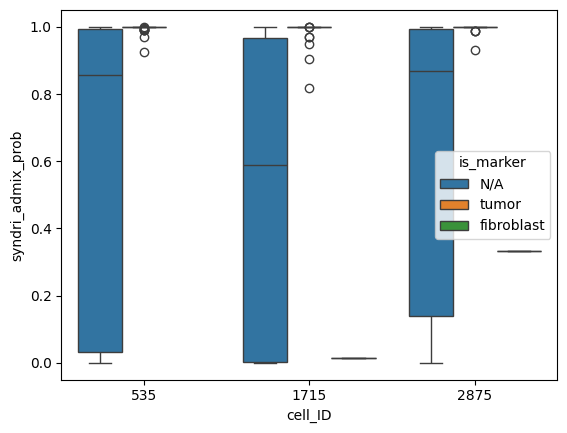

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=tx_removed_df,x='cell_ID',y='syndri_admix_prob',hue='is_marker')

32.0
[1, 2, 3, 4, 5, 6, 7, 8, 9]
3 1


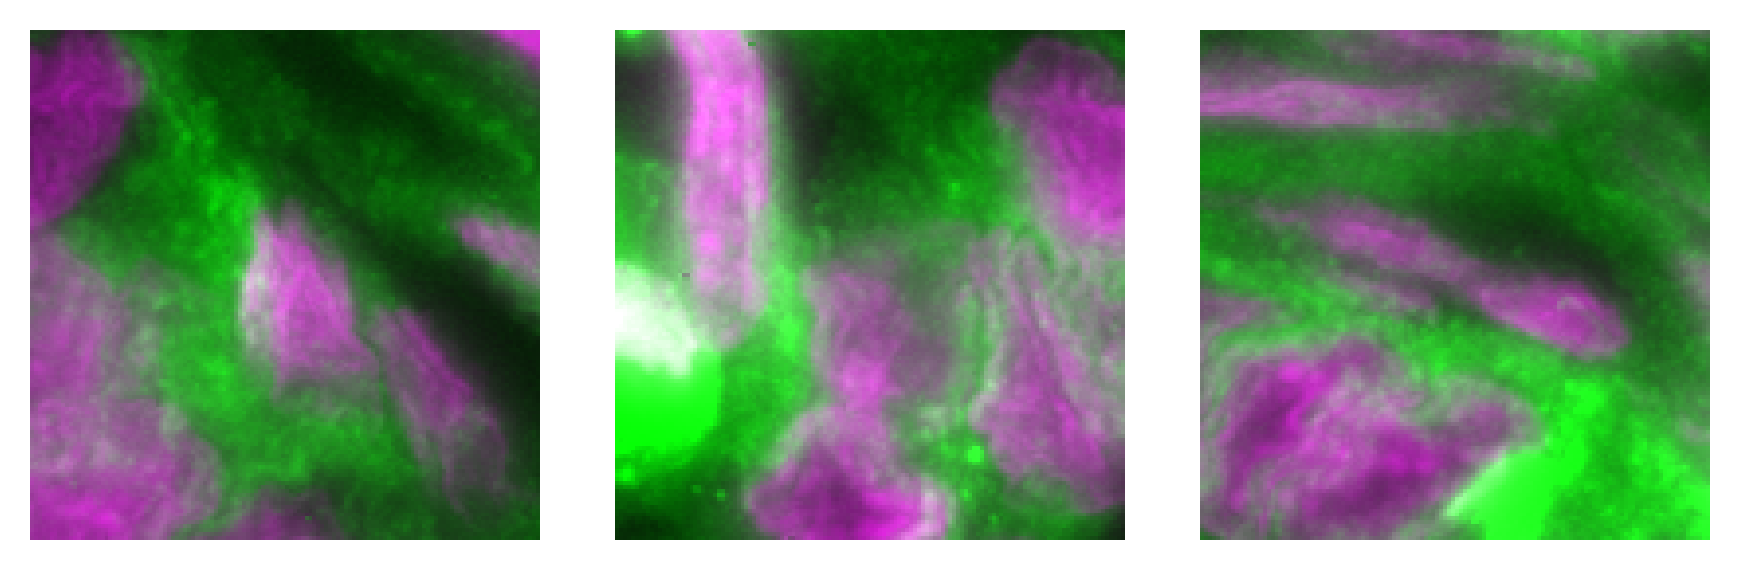

In [33]:
import tifffile
import importlib
import sys
sys.path.append('/home/jwinchel/Syndri/code')
from plotting import plot_cell_crops_with_tx, load_z_projected_image

importlib.reload(sys.modules['plotting'])
# parse images
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-RawMorphologyImages/'
files = sorted([f for f in os.listdir(img_dir)])
print(len(files)/9)
img_df = pd.DataFrame({'filename':files})
img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-2][1:]))
img_df['z'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-1][1:]))
img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
img_df.head()
# raw = tifffile.imread(img_df[img_df["fov"] == 26].iloc[4]["filepath"])  # (C,H,W)
# print(raw.shape)
raw = load_z_projected_image(img_df,fov=26)
#
marker_dict = {'tumor':'^','fibroblast':'o','N/A':'s'}
palette_dict = {'tumor':'red','fibroblast':'blue','N/A':'gray'}
fig, axes = plot_cell_crops_with_tx(
    raw,
    cell_df=sample_cells,
    tx_df=tx_df.head(n=5),
    n_cells=3,
    ncols=3,
    crop_size=130,
    label_col="is_marker",
    ch_purple=4,
    ch_green=0,
    y_origin="bottom",   
    s=5,
    random_state=None,
    dpi=300,
    figsize=(6,2),
    markers=marker_dict,
    palette=palette_dict,
    legend=False
)
# fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True)
fig.tight_layout()
